In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [4]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 4       , 60 ),
    ('B'     , '---'      , 8       , 40 ),
    ('C'     , '---'      , 4       , 30 ),
    ('D'     , 'A,B,C'    , 1       , 40 ),
    ('E'     , 'D'        , 6       , 30 ),
    ('F'     , 'D'        , 5       , 20 ),
    ('G'     , 'E'        , 4       , 30 ),
    ('H'     , 'F,G'      , 2       , 30 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,4,60
B,---,8,40
C,---,4,30
D,"A,B,C",1,40
E,D,6,30
F,D,5,20
G,E,4,30
H,"F,G",2,30


Al final de la semana 10 se realiza un punto de control. Para cada actividad se anotan las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [5]:
#| tbl-cap: "Datos del punto de control (final de la semana 10)"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 5              , 72, 100      ),
    ('B'     , 10             , 30, 62       ),
    ('C'     , 8              , 36, 100      ),
    ('D'     , 0              , 0 , 0        ),
    ('E'     , 0              , 0 , 0        ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,5,72,100
B,10,30,62
C,8,36,100
D,0,0,0
E,0,0,0
F,0,0,0
G,0,0,0
H,0,0,0


In [6]:
pregunta_1 = "1. Dibuje los tres diagramas de Gantt del valor ganado: valor planificado (PV), valor ganado (EV) y coste real (AC).  "
pregunta_2 = "2. Calcule PV, EV y AC en el punto de control, las variaciones CV y SV y los índices CPI y SPI. Interprete la situación del proyecto.  "
pregunta_3 = "3. Estime el coste final del proyecto (EAC) con tres hipótesis: (a) el resto se ejecuta según presupuesto, (b) se mantiene la eficiencia en coste actual, (c) se mantienen las eficiencias en coste y en plazo. Calcule la variación al final (VAC) en cada caso.  "
pregunta_4 = "4. Calcule el índice de rendimiento necesario para terminar en presupuesto (TCPI). ¿Es realista?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje los tres diagramas de Gantt del valor ganado: valor planificado (PV), valor ganado (EV) y coste real (AC).  

2. Calcule PV, EV y AC en el punto de control, las variaciones CV y SV y los índices CPI y SPI. Interprete la situación del proyecto.  

3. Estime el coste final del proyecto (EAC) con tres hipótesis: (a) el resto se ejecuta según presupuesto, (b) se mantiene la eficiencia en coste actual, (c) se mantienen las eficiencias en coste y en plazo. Calcule la variación al final (VAC) en cada caso.  

4. Calcule el índice de rendimiento necesario para terminar en presupuesto (TCPI). ¿Es realista?  

# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

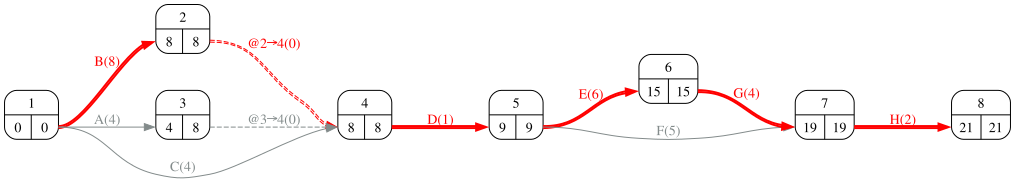

In [8]:
#| fig-cap: "Grafo PERT de la planificación"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje los tres diagramas de Gantt del valor ganado: valor planificado (PV), valor ganado (EV) y coste real (AC).  

En el Gantt del valor planificado cada casilla lleva el coste planificado de la semana (BAC / duración). En el del valor ganado, el BAC multiplicado por el porcentaje realizado se reparte entre las semanas trabajadas. En el del coste real, el coste incurrido entre las semanas trabajadas.

In [10]:
datos_valor_ganado = pd.concat([datos_proyecto, seguimiento], axis=1)
vg = EarnedValue(proyecto)
gantts = vg.calcula_gantts(datos_valor_ganado, planned_durations_label='duration',
                           actual_durations_label='actual_duration', PV_label='BAC', AC_label='AC',
                           percentage_complete_label='performed', tikz=True,
                           params=dict(period_width=1, row_height=0.7, activity_relative_height=0.6, **GANTT_PARAMS,
                                       critical_background_color='white!90!green', regular_background_color='white!90!green',
                                       regular_text_color='black', critical_text_color='black'))

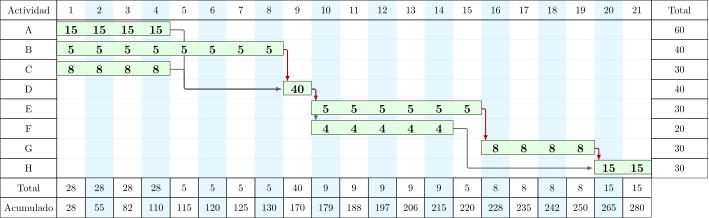

In [11]:
#| fig-cap: "PV: valor planificado"
#| label: fig-ganttPV
pinta_tikz(gantts['gantt_PV'])

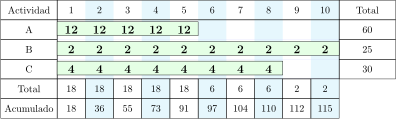

In [12]:
#| fig-cap: "EV: valor ganado"
#| label: fig-ganttEV
pinta_tikz(gantts['gantt_EV'])

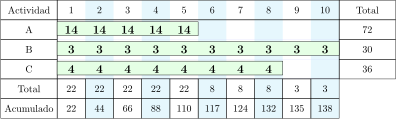

In [13]:
#| fig-cap: "AC: coste real"
#| label: fig-ganttAC
pinta_tikz(gantts['gantt_AC'])

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Calcule PV, EV y AC en el punto de control, las variaciones CV y SV y los índices CPI y SPI. Interprete la situación del proyecto.  

In [15]:
semana_control = 10
acumulados = gantts['acumulados']
PV = float(acumulados.loc[semana_control, 'PV'])
EV = float((datos_valor_ganado['BAC'] * datos_valor_ganado['performed'] / 100).sum())
AC = float(datos_valor_ganado['AC'].sum())
CV, SV = EV - AC, EV - PV
CPI, SPI = EV / AC, EV / PV
pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': CV, 'SV': SV, 'CPI': CPI, 'SPI': SPI, 'BAC': BAC_total}).round(3).to_frame('valor').T

,PV,EV,AC,CV,SV,CPI,SPI,BAC
valor,179.0,114.8,138.0,-23.2,-64.2,0.832,0.641,280.0


De dónde salen las tres cifras: el valor planificado de cada actividad es su BAC por la fracción de su duración que debería haberse ejecutado en la semana de control (según el calendario de inicios más tempranos); el valor ganado, su BAC por el porcentaje realizado; el coste real, lo gastado en ella.

In [16]:
#| tbl-cap: "PV, EV y AC actividad a actividad en el punto de control"
#| label: tbl-valorGanadoPaso
calendario_plan = proyecto.calendar(datos_proyecto['duration'])
detalle_vg = detalle_valor_ganado(datos_valor_ganado, calendario_plan, semana_control)
detalle_vg[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']]

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,60.0,4 de 4,60·1.00 = 60.0,100,60·1.00 = 60.0,72.0
B,40.0,8 de 8,40·1.00 = 40.0,62,40·0.62 = 24.8,30.0
C,30.0,4 de 4,30·1.00 = 30.0,100,30·1.00 = 30.0,36.0
D,40.0,1 de 1,40·1.00 = 40.0,0,40·0.00 = 0.0,0.0
E,30.0,1 de 6,30·0.17 = 5.0,0,30·0.00 = 0.0,0.0
F,20.0,1 de 5,20·0.20 = 4.0,0,20·0.00 = 0.0,0.0
G,30.0,0 de 4,30·0.00 = 0.0,0,30·0.00 = 0.0,0.0
H,30.0,0 de 2,30·0.00 = 0.0,0,30·0.00 = 0.0,0.0


In [17]:
Markdown(f'''Sumando las columnas: PV = {detalle_vg["PV_i"].sum():.1f}, EV = {detalle_vg["EV_i"].sum():.1f}, AC = {detalle_vg["AC"].sum():.1f} k€. Y con ellas:

- CV = EV − AC = {EV:.1f} − {AC:.1f} = {CV:.1f} k€
- SV = EV − PV = {EV:.1f} − {PV:.1f} = {SV:.1f} k€
- CPI = EV / AC = {EV:.1f} / {AC:.1f} = {CPI:.3f}
- SPI = EV / PV = {EV:.1f} / {PV:.1f} = {SPI:.3f}''')

Sumando las columnas: PV = 179.0, EV = 114.8, AC = 138.0 k€. Y con ellas:

- CV = EV − AC = 114.8 − 138.0 = -23.2 k€
- SV = EV − PV = 114.8 − 179.0 = -64.2 k€
- CPI = EV / AC = 114.8 / 138.0 = 0.832
- SPI = EV / PV = 114.8 / 179.0 = 0.641

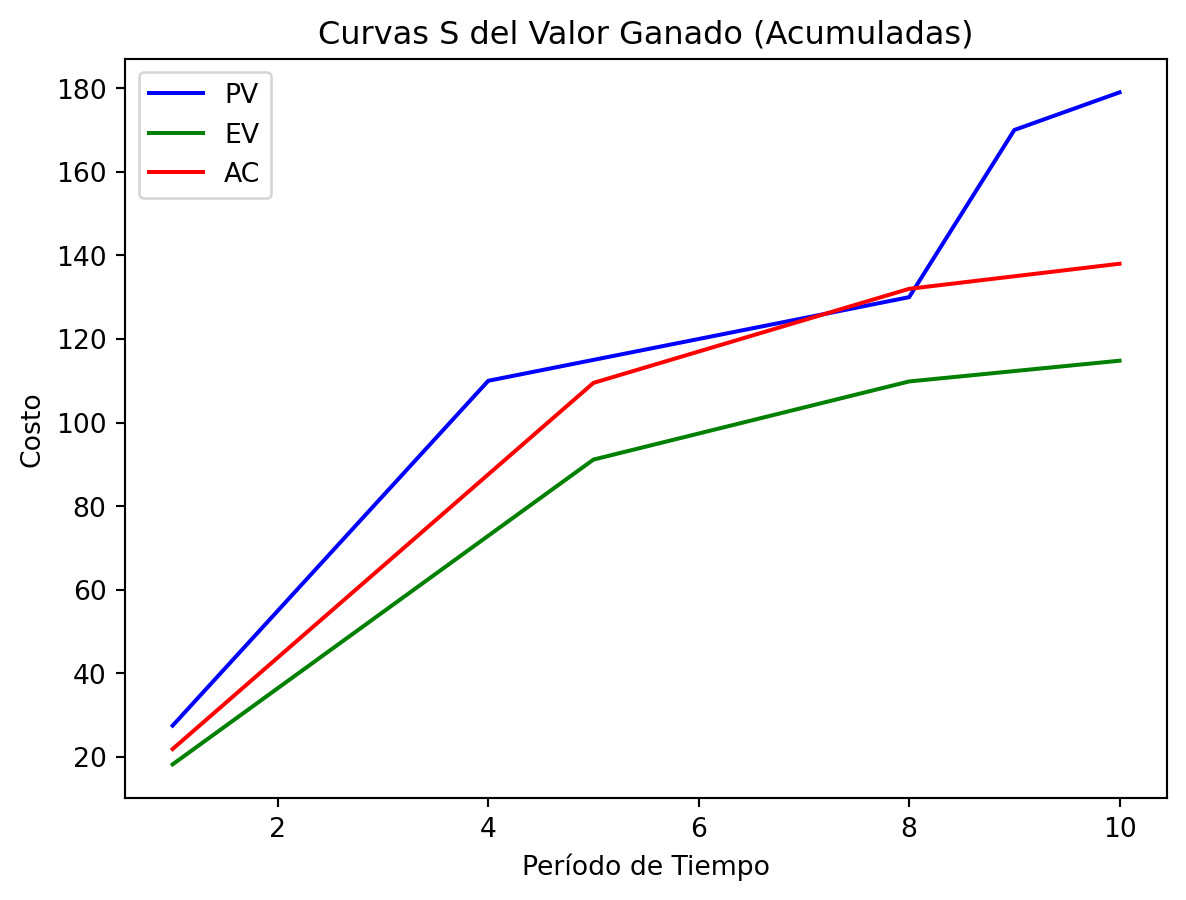

In [18]:
#| fig-cap: "Curvas S del proyecto"
#| label: fig-curvasS
plot_curvas_valor_ganado(gantts)

In [19]:
Markdown(f'''En la semana {semana_control} se ha ganado valor por {EV:.1f} k€ frente a los {PV:.1f} planificados (SV = {SV:.1f}, SPI = {SPI:.2f}: {"retraso" if SPI < 1 else "adelanto"}) y se han gastado {AC:.1f} k€ (CV = {CV:.1f}, CPI = {CPI:.2f}: por cada euro gastado se obtienen {CPI:.2f} euros de valor, {"sobrecoste" if CPI < 1 else "ahorro"}).''')

En la semana 10 se ha ganado valor por 114.8 k€ frente a los 179.0 planificados (SV = -64.2, SPI = 0.64: retraso) y se han gastado 138.0 k€ (CV = -23.2, CPI = 0.83: por cada euro gastado se obtienen 0.83 euros de valor, sobrecoste).

## Apartado 3

In [20]:
display(Markdown(pregunta_3))

3. Estime el coste final del proyecto (EAC) con tres hipótesis: (a) el resto se ejecuta según presupuesto, (b) se mantiene la eficiencia en coste actual, (c) se mantienen las eficiencias en coste y en plazo. Calcule la variación al final (VAC) en cada caso.  

Las tres previsiones habituales del coste final:

- (a) $EAC = AC + (BAC - EV)$: el trabajo restante costará lo presupuestado.
- (b) $EAC = BAC / CPI = AC + (BAC - EV)/CPI$: se mantiene la eficiencia en coste.
- (c) $EAC = AC + (BAC - EV)/(CPI \cdot SPI)$: el retraso también encarece el resto.

En todas, $VAC = BAC - EAC$.

In [21]:
previsiones = pd.DataFrame({
    '(a) resto según presupuesto': [AC + (BAC_total - EV)],
    '(b) misma eficiencia en coste': [BAC_total / CPI],
    '(c) misma eficiencia en coste y plazo': [AC + (BAC_total - EV) / (CPI * SPI)]},
    index=['EAC']).T
previsiones['VAC'] = BAC_total - previsiones['EAC']
previsiones.round(1)

,EAC,VAC
(a) resto según presupuesto,303.2,-23.2
(b) misma eficiencia en coste,336.6,-56.6
(c) misma eficiencia en coste y plazo,447.6,-167.6


In [22]:
Markdown(f'La hipótesis (a) es la más optimista: supone que los problemas no se repetirán. La (c) es la más pesimista. Lo habitual es tomar (b) como previsión central: {BAC_total / CPI:.1f} k€ frente a los {BAC_total:.0f} presupuestados.')

La hipótesis (a) es la más optimista: supone que los problemas no se repetirán. La (c) es la más pesimista. Lo habitual es tomar (b) como previsión central: 336.6 k€ frente a los 280 presupuestados.

## Apartado 4

In [23]:
display(Markdown(pregunta_4))

4. Calcule el índice de rendimiento necesario para terminar en presupuesto (TCPI). ¿Es realista?  

$TCPI = \dfrac{BAC - EV}{BAC - AC}$: eficiencia en coste que habría que mantener en lo que queda para terminar exactamente en presupuesto.

In [24]:
TCPI = (BAC_total - EV) / (BAC_total - AC)
Markdown(f'TCPI = ({BAC_total:.0f} − {EV:.1f}) / ({BAC_total:.0f} − {AC:.1f}) = {TCPI:.2f}. '
         f'Hasta ahora el proyecto rinde CPI = {CPI:.2f}; pasar a {TCPI:.2f} exige una mejora de '
         f'{(TCPI / CPI - 1) * 100:.0f} %, {"poco realista sin cambios de fondo" if TCPI > 1.1 else "alcanzable con medidas correctoras"}.')

TCPI = (280 − 114.8) / (280 − 138.0) = 1.16. Hasta ahora el proyecto rinde CPI = 0.83; pasar a 1.16 exige una mejora de 40 %, poco realista sin cambios de fondo.